# 🩺 GluCare AI - Data Cleaning & Ground Truth Labeling Pipeline
### NHANES 2021–2023 Raw Data to Clean Clinical Model Dataset (Step 1 s/d Step 6)

Notebook ini mendokumentasikan seluruh tahapan kerja data engineering GluCare AI:
- **Step 1**: Inisialisasi arsitektur direktori repositori `glucare_ai/`.
- **Step 2**: Akuisisi 8 domain file mentah NHANES (`DEMO`, `BMX`, `BPXO`, `GLU`, `HDL`, `TRIGLY`, `GHB`, `FASTQX`).
- **Step 3**: Penggabungan tabel multi-domain berbasis `SEQN`.
- **Step 4**: Clinical feature engineering (MAP, rasio TG/HDL, rata-rata tekanan darah).
- **Step 5**: Pembersihan data (validasi puasa 8–24 jam, eksklusi kehamilan, segmentasi usia 20–40 tahun, 0 nulls).
- **Step 6**: **Penentuan Ground Truth Klinis (Opsi A)**: Menetapkan `label_prediabetes = 1` (Prediabetes), `label_prediabetes = 0` (Bukan Prediabetes), dan mengeksklusi kasus diabetes murni agar AI fokus pada skrining dini prediabetes.

In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Tambahkan root glucare_ai ke sys.path
BASE_DIR = Path.cwd().parent
if str(BASE_DIR) not in sys.path:
    sys.path.append(str(BASE_DIR))

RAW_DIR = BASE_DIR / 'data' / 'raw' / 'nhanes_2021_2023'
PROCESSED_DIR = BASE_DIR / 'data' / 'processed'

print(f'Raw data directory: {RAW_DIR.resolve()}')
print(f'Processed data directory: {PROCESSED_DIR.resolve()}')

Raw data directory: D:\INFINIT LEARNING\Glucare_backend_pribadi\main-feature\glucare_ai\data\raw\nhanes_2021_2023
Processed data directory: D:\INFINIT LEARNING\Glucare_backend_pribadi\main-feature\glucare_ai\data\processed


## Step 1 & 2: Membaca File Mentah SAS XPT (8 Modul NHANES)

In [2]:
from src.data_preprocessing import load_raw_nhanes_data

raw_dfs = load_raw_nhanes_data(RAW_DIR)

Loading raw NHANES XPT files from: d:\INFINIT LEARNING\Glucare_backend_pribadi\main-feature\glucare_ai\data\raw\nhanes_2021_2023
  - Loaded DEMO_L.XPT: 11,933 rows, 27 columns
  - Loaded BMX_L.XPT: 8,860 rows, 22 columns
  - Loaded BPXO_L.XPT: 7,801 rows, 12 columns
  - Loaded GLU_L.XPT: 3,996 rows, 4 columns
  - Loaded HDL_L.XPT: 8,068 rows, 4 columns
  - Loaded TRIGLY_L.XPT: 3,996 rows, 10 columns
  - Loaded GHB_L.XPT: 7,199 rows, 3 columns
  - Loaded FASTQX_L.XPT: 8,727 rows, 19 columns


## Step 3: Penggabungan Tabel Berdasarkan `SEQN` (Inner Join)

In [3]:
from src.data_preprocessing import merge_nhanes_tables

merged_df = merge_nhanes_tables(raw_dfs)
print(f'Total baris gabungan: {len(merged_df):,}')
merged_df.head()


Successfully merged tables on SEQN. Total records: 3,996
Total baris gabungan: 3,996


,SEQN,RIDAGEYR,RIAGENDR,RIDEXPRG,BMXWT,BMXHT,BMXBMI,BMXWAIST,BPXOSY1,BPXOSY2,BPXOSY3,BPXODI1,BPXODI2,BPXODI3,LBXGLU,LBDHDD,LBXTLG,LBXGH,PHAFSTHR
0,130378.0,43.0,1.0,NaN,86.9,179.5,27.0,98.3,135.0,131.0,132.0,98.0,96.0,94.0,113.0,45.0,153.0,5.6,14.0
1,130379.0,66.0,1.0,NaN,101.8,174.2,33.5,114.7,121.0,117.0,113.0,84.0,76.0,76.0,99.0,60.0,86.0,5.6,2.0
2,130380.0,44.0,2.0,2.0,69.4,152.9,29.7,93.5,111.0,112.0,104.0,79.0,80.0,76.0,156.0,49.0,375.0,6.2,11.0
3,130386.0,34.0,1.0,NaN,90.6,173.3,30.2,106.1,110.0,120.0,115.0,72.0,74.0,75.0,100.0,46.0,142.0,5.1,14.0
4,130394.0,51.0,1.0,NaN,76.7,177.3,24.4,92.1,99.0,110.0,123.0,69.0,68.0,67.0,88.0,48.0,57.0,4.8,13.0


## Step 4: Clinical Feature Engineering
- Tekanan Darah Rata-rata Sistolik & Diastolik
- Mean Arterial Pressure (MAP)
- Rasio Trigliserida / HDL (TG/HDL Ratio)
- Fallback Perhitungan BMI

In [4]:
from src.data_preprocessing import engineer_clinical_features

engineered_df = engineer_clinical_features(merged_df)
cols = ['seqn', 'age', 'gender', 'bmi', 'bp_systolic', 'bp_diastolic', 'map_pressure', 'glucose_fasting', 'hdl', 'triglycerides', 'tg_hdl_ratio', 'hba1c', 'ground_truth_status', 'label_prediabetes']
engineered_df[cols].head()

,seqn,age,gender,bmi,bp_systolic,bp_diastolic,map_pressure,glucose_fasting,hdl,triglycerides,tg_hdl_ratio,hba1c,ground_truth_status,label_prediabetes
0,130378,43,1,27.0,132.666667,96.000000,108.222222,113.0,45.0,153.0,3.400000,5.6,Prediabetes,1.0
1,130379,66,1,33.5,117.000000,78.666667,91.444444,99.0,60.0,86.0,1.433333,5.6,Bukan Prediabetes,0.0
2,130380,44,2,29.7,109.000000,78.333333,88.555556,156.0,49.0,375.0,7.653061,6.2,Diabetes,NaN
3,130386,34,1,30.2,115.000000,73.666667,87.444444,100.0,46.0,142.0,3.086957,5.1,Prediabetes,1.0
4,130394,51,1,24.4,110.666667,68.000000,82.222222,88.0,48.0,57.0,1.187500,4.8,Bukan Prediabetes,0.0


## Step 5 & Step 6: Data Cleaning, Segmentasi Usia 20–40 Tahun, dan Ground Truth (Opsi A)
- Validasi puasa (8–24 jam)
- Eksklusi kehamilan (`RIDEXPRG == 1`)
- Filter usia target GluCare: 20–40 tahun
- **Opsi A**: Eksklusi peserta diabetes murni agar AI berfokus murni pada pemisahan individu sehat (`label = 0`) dan prediabetes (`label = 1`).

In [5]:
from src.data_preprocessing import clean_dataset

# Dataset Target GluCare Usia 20-40 Tahun (Opsi A)
target_20_40 = clean_dataset(
    engineered_df,
    min_age=20,
    max_age=40,
    exclude_pregnant=True,
    exclude_diabetes=True, # Opsi A
    min_fasting_hours=8.0
)
target_20_40.to_csv(PROCESSED_DIR / 'nhanes_glucare_target_20_40.csv', index=False)

# Dataset Dewasa Lengkap (Usia >= 20 Tahun, Komparatif)
cleaned_adult = clean_dataset(
    engineered_df,
    min_age=20,
    max_age=None,
    exclude_pregnant=True,
    exclude_diabetes=False,
    min_fasting_hours=8.0
)
cleaned_adult.to_csv(PROCESSED_DIR / 'nhanes_glucare_cleaned_adult.csv', index=False)

  - Option A applied: Excluded pure diabetes participants.

[Cleaning Summary for age 20-40]:
  - Initial merged records: 3,996
  - After deduplication: 3,996
  - After pregnancy exclusion: 3,968
  - After fasting compliance (8-24h): 3,543
  - After age filtering: 793
  - Final clean records (0 nulls): 653

Ground Truth Distribution (Step 6):
  - Bukan Prediabetes: 408 (62.5%)
  - Prediabetes: 245 (37.5%)

[Cleaning Summary for age 20-all]:
  - Initial merged records: 3,996
  - After deduplication: 3,996
  - After pregnancy exclusion: 3,968
  - After fasting compliance (8-24h): 3,543
  - After age filtering: 3,075
  - Final clean records (0 nulls): 2,661

Ground Truth Distribution (Step 6):
  - Prediabetes: 1,311 (49.3%)
  - Bukan Prediabetes: 943 (35.4%)
  - Diabetes: 407 (15.3%)


## Visualisasi Distribusi Ground Truth Step 6

C:\Users\Advan\AppData\Local\Temp\ipykernel_8352\1292420799.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=target_20_40, x='ground_truth_status', palette=['#3182CE', '#E53E3E'])


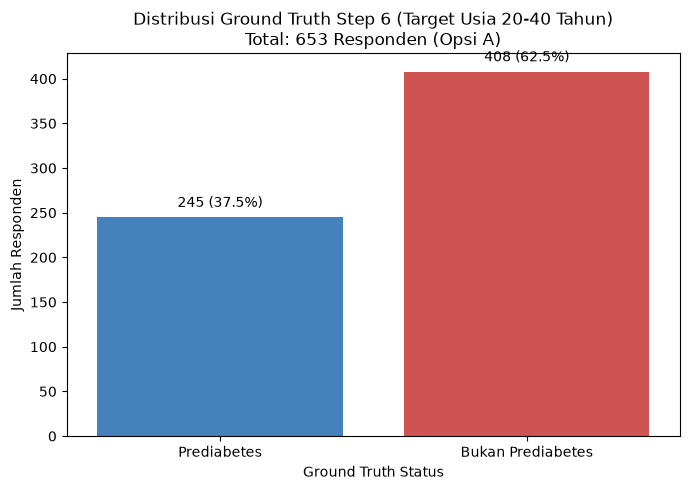

In [6]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=target_20_40, x='ground_truth_status', palette=['#3182CE', '#E53E3E'])
plt.title(f'Distribusi Ground Truth Step 6 (Target Usia 20-40 Tahun)\nTotal: {len(target_20_40):,} Responden (Opsi A)')
plt.xlabel('Ground Truth Status')
plt.ylabel('Jumlah Responden')
for p in ax.patches:
    h = p.get_height()
    ax.annotate(f'{int(h)} ({(h/len(target_20_40))*100:.1f}%)',
                (p.get_x() + p.get_width() / 2., h),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')
plt.tight_layout()
plt.show()

## Ringkasan Akhir Dataset Step 6

In [7]:
print('=== Info Dataset Step 6 (Target Usia 20-40 Tahun) ===')
print(target_20_40.info())
print('\n=== Frekuensi Label Prediabetes ===')
print(target_20_40['label_prediabetes'].value_counts())

=== Info Dataset Step 6 (Target Usia 20-40 Tahun) ===
<class 'pandas.DataFrame'>
RangeIndex: 653 entries, 0 to 652
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   seqn                 653 non-null    int64  
 1   age                  653 non-null    int64  
 2   gender               653 non-null    int64  
 3   weight               653 non-null    float64
 4   height               653 non-null    float64
 5   bmi                  653 non-null    float64
 6   waist_cm             653 non-null    float64
 7   bp_systolic          653 non-null    float64
 8   bp_diastolic         653 non-null    float64
 9   map_pressure         653 non-null    float64
 10  glucose_fasting      653 non-null    float64
 11  hdl                  653 non-null    float64
 12  triglycerides        653 non-null    float64
 13  tg_hdl_ratio         653 non-null    float64
 14  hba1c                653 non-null    float64
 1